# 01 – Eksploracja danych PSE: zapotrzebowanie na moc w KSE

Cel: sprawdzić, jak wyglądają dane z API PSE (`kse-load`) dla jednej doby,
zanim pobierzemy dłuższy okres do modelu prognozy godzinowej.

Źródło: https://api.raporty.pse.pl/api/kse-load (bez klucza API, dane od 14.06.2024)

In [5]:
import requests
import pandas as pd

In [6]:
url = "https://api.raporty.pse.pl/api/kse-load"
params = {"$filter": "business_date eq '2026-10-23'"}  # jeden dzień

response = requests.get(url, params=params, timeout=30)
print(response.status_code)  # 200 = OK

200


In [7]:
data = response.json()
df = pd.DataFrame(data["value"])  # wiersze są w kluczu "value"
print("Liczba wierszy:", len(df))
print("Następna strona?", data.get("nextLink"))  # None = wszystko w jednej odpowiedzi

Liczba wierszy: 96
Następna strona? None


In [8]:
df["dtime"] = pd.to_datetime(df["dtime"])  # tekst -> data i godzina
print(df.shape)
print(df.columns.tolist())
df.head()

(96, 9)
['dtime', 'period', 'dtime_utc', 'load_fcst', 'period_utc', 'load_actual', 'business_date', 'publication_ts', 'publication_ts_utc']


,dtime,period,dtime_utc,load_fcst,period_utc,load_actual,business_date,publication_ts,publication_ts_utc
0,2026-10-23 00:15:00,00:00 - 00:15,2026-10-22 22:15:00,17000.0,22:00 - 22:15,17073.438,2026-10-23,2026-10-24 03:05:06.330,2026-10-24 01:05:06.330
1,2026-10-23 00:30:00,00:15 - 00:30,2026-10-22 22:30:00,16800.0,22:15 - 22:30,17060.857,2026-10-23,2026-10-24 03:05:06.330,2026-10-24 01:05:06.330
2,2026-10-23 00:45:00,00:30 - 00:45,2026-10-22 22:45:00,16600.0,22:30 - 22:45,16722.246,2026-10-23,2026-10-24 03:05:06.330,2026-10-24 01:05:06.330
3,2026-10-23 01:00:00,00:45 - 01:00,2026-10-22 23:00:00,16450.0,22:45 - 23:00,16683.621,2026-10-23,2026-10-24 03:05:06.330,2026-10-24 01:05:06.330
4,2026-10-23 01:15:00,01:00 - 01:15,2026-10-22 23:15:00,16300.0,23:00 - 23:15,16562.498,2026-10-23,2026-10-24 03:05:06.330,2026-10-24 01:05:06.330


## Dane

Jedna doba = **96 wierszy** (rozdzielczość 15 minut) i 9 kolumn. Najważniejsze:

| Kolumna | Znaczenie |
|---|---|
| `dtime` | koniec 15-minutowego okresu, czas lokalny (00:15 = okres 00:00–00:15) |
| `dtime_utc` | to samo w UTC; tego używamy w modelu, bo nie psują go zmiany czasu |
| `load_actual` | rzeczywiste zapotrzebowanie na moc [MW], **zmienna docelowa** |
| `load_fcst` | prognoza PSE [MW], **benchmark** do pobicia |
| `business_date` | doba handlowa, której dotyczą dane |

Uwaga: w dniu zmiany czasu doba ma 92 lub 100 wierszy, dlatego czas liczymy w UTC.

Text(0.5, 1.0, 'Zapotrzebowanie KSE, 2026-10-23')

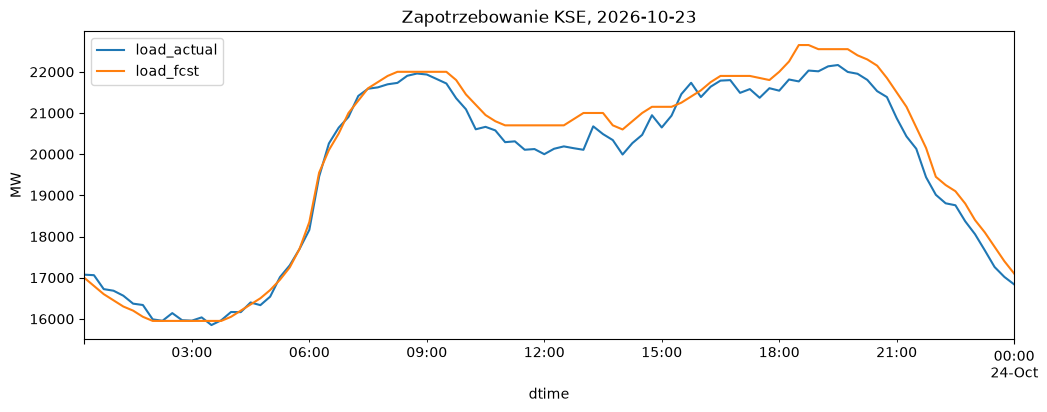

In [9]:
ax = df.plot(x="dtime", y=["load_actual", "load_fcst"], figsize=(12, 4))
ax.set_ylabel("MW")
ax.set_title("Zapotrzebowanie KSE, 2026-10-23")

## Obserwacje (23.10.2026)

- **Profil dobowy:** minimum w nocy (~16 000 MW, 2:00–4:00), gwałtowny wzrost
  między 5:00 a 8:00, dwa szczyty: poranny (~9:00) i wieczorny (~19:00–20:00, >22 000 MW).
- **Spadek w południe** (~20 000 MW, 11:00–14:00): prawdopodobnie efekt fotowoltaiki
  prosumenckiej, która obniża zapotrzebowanie widziane przez sieć.
  Wniosek: w modelu warto użyć nasłonecznienia i zachmurzenia z Open-Meteo.
- **Prognoza PSE:** bardzo dokładna w nocy i rano, po południu i wieczorem
  przeszacowuje o kilkaset MW.
- **Średni błąd prognozy PSE (MAE):** 318 MW, to wartość do pobicia przez nasz model.

Następny krok: pobrać wiele dni (funkcja `fetch_load` w `src/pse_client.py`).

In [10]:
blad = (df["load_fcst"] - df["load_actual"]).abs()
print("Średni błąd bezwzględny (MAE):", round(blad.mean()), "MW")

Średni błąd bezwzględny (MAE): 318 MW


In [11]:
import sys
sys.path.append("..")  # notebook jest w notebooks/, a src/ piętro wyżej
from src.pse_client import fetch_load

df_week = fetch_load("2026-10-01", "2026-10-07")
print(len(df_week))  # oczekujemy 7 × 96 = 672

672


Text(0.5, 1.0, 'Zapotrzebowanie KSE, 1–7.10.2026')

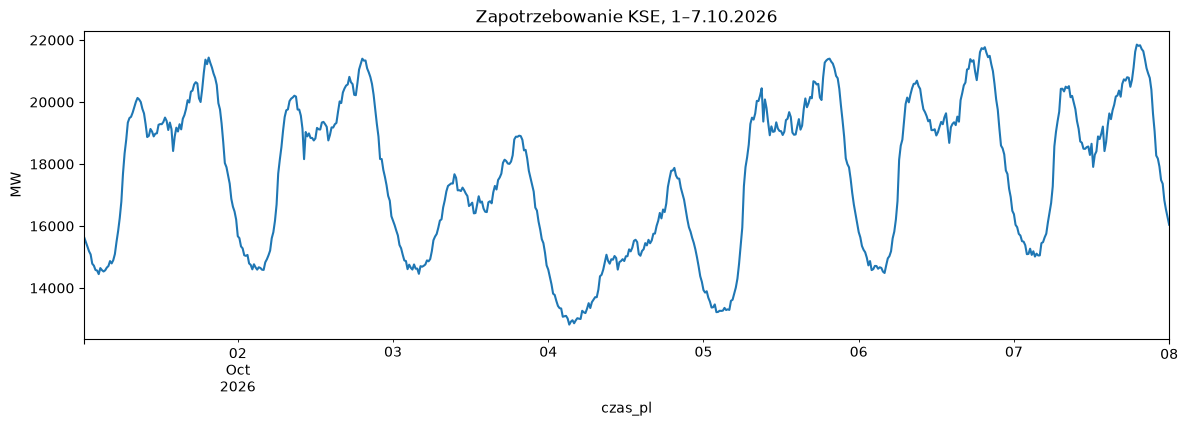

In [12]:
# do wykresu dla ludzi zamieniamy UTC na czas polski
df_week["czas_pl"] = df_week["dtime_utc"].dt.tz_convert("Europe/Warsaw")

ax = df_week.plot(x="czas_pl", y="load_actual", figsize=(14, 4), legend=False)
ax.set_ylabel("MW")
ax.set_title("Zapotrzebowanie KSE, 1–7.10.2026")

dzien
Thu 01.10    18286.0
Fri 02.10    18345.0
Sat 03.10    16547.0
Sun 04.10    14919.0
Mon 05.10    18004.0
Tue 06.10    18601.0
Wed 07.10    18563.0
Name: load_actual, dtype: float64


<Axes: title={'center': 'Średnie zapotrzebowanie dzienne'}, xlabel='dzien', ylabel='MW'>

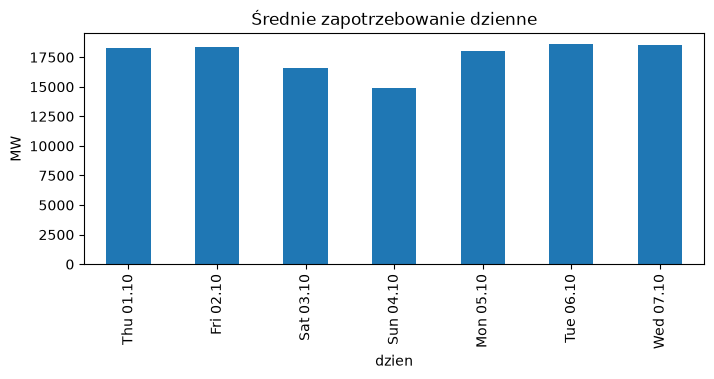

In [13]:
df_week["dzien"] = pd.to_datetime(df_week["business_date"]).dt.strftime("%a %d.%m")
srednie = df_week.groupby("dzien", sort=False)["load_actual"].mean().round()
print(srednie)
srednie.plot(kind="bar", figsize=(8, 3), ylabel="MW", title="Średnie zapotrzebowanie dzienne")

## Obserwacje: tydzień 1–7.10.2026

| Dzień | Średnie zapotrzebowanie [MW] | vs średnia dni roboczych |
|---|---|---|
| Dni robocze (czw–pt, pon–śr) | ~18 360 | — |
| Sobota 03.10 | 16 564 | **−10%** |
| Niedziela 04.10 | 14 926 | **−19%** |

- **Efekt weekendu jest bardzo silny:** w niedzielę zapotrzebowanie jest średnio
  o ~19% niższe niż w dzień roboczy, a w sobotę o ~10%.
- **Szczyty:** w dni robocze wieczorny szczyt sięga ~21 500 MW,
  w sobotę ~19 000 MW, a w niedzielę tylko ~17 800 MW.
- **Noc:** najniższe minimum tygodnia przypada w nocy z soboty na niedzielę (~12 900 MW).
- **Poranny wzrost** w weekend jest łagodniejszy i zaczyna się później (brak dojazdów i pracy zakładów).
- **Poniedziałek** jest nieco niższy od pozostałych dni roboczych (~−2%), widać „rozruch” po weekendzie.

**Wniosek dla modelu:** dzień tygodnia (lub przynajmniej flaga „dzień roboczy”)
to jedna z najważniejszych cech. Święta zachowują się prawdopodobnie jak niedziela,
więc potrzebny będzie kalendarz świąt w Polsce.

Uwaga techniczna: dni grupujemy po `business_date`, bo `dtime` = koniec okresu
(00:00 należy do poprzedniej doby).